In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from tqdm import tqdm
import pandas as pd
from IPython.display import display


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import utils.util_freesurfer_segmentation as util_freesurfer
from PIL import Image
import random

np.set_printoptions(precision=4)

import constants as cts

# import pathlib
# path = "a/b\\\\c"
# path = pathlib.Path(path).as_posix()
# print(path)

SERVER: False


# Create images center test 2D

In [2]:

def create_and_save_2D_images(img_3D, img_2d_path_name, scale_intensity=True, axis=0):
    # prepare RGB image
    img_2D_list = fc.get_2D_slides_from_3D_volume(img_3D, pil.LAYER_START_2D, pil.LAYER_END_2D, axis=axis)
    for i, img_2D in enumerate(img_2D_list):
        _current_layer = pil.LAYER_START_2D + i
        img_to_save = img_2D
        if scale_intensity:
            img_to_save *= 255.0
 
        img = Image.fromarray(img_to_save.astype(dtype=np.uint8))
        img.save(img_2d_path_name.format(_current_layer))

def create_and_save_2D_images_all_patients(matching_ids, axis=2):
    axial = axis==2
    for id in tqdm(matching_ids):
        for hunt in [3,4]:

            # load image
            img_3D = nfc.load_nifti(cts.get_registered_image_path_name(hunt, id))[0]
            bmask_3D = nfc.load_nifti(cts.get_registered_bmask_path_name(hunt, id))[0]
            seg_3D = nfc.load_nifti(cts.get_registered_seg3_path_name(hunt, id))[0]

            if fc.verify_folder(pil.get_patient_folder_2D(hunt, id, axial=axial, absolute=True), create=True):
                create_and_save_2D_images(img_3D, pil.get_2D_image_path_name(hunt, id, "{0}", pil.INAME2D_T1, axial=axial, absolute=True), axis=axis)
                create_and_save_2D_images(bmask_3D, pil.get_2D_image_path_name(hunt, id, "{0}", pil.INAME2D_BMASK, axial=axial, absolute=True), axis=axis)
                create_and_save_2D_images(seg_3D, pil.get_2D_image_path_name(hunt, id, "{0}", pil.INAME2D_SEG_3, axial=axial, absolute=True), scale_intensity=False, axis=axis)
    
matching_ids = pil.get_matching_ids()
create_and_save_2D_images_all_patients(matching_ids)



  0%|          | 0/703 [00:00<?, ?it/s]

100%|██████████| 703/703 [12:34<00:00,  1.07s/it]


In [ ]:
img_path_name = pil.get_2D_image_path_name(3, "00039", 97, pil.INAME2D_T1, absolute=True)
imagen = np.array(Image.open(img_path_name))
print(util.get_basic_metrics_str(imagen))
print(np.unique(imagen))


min: 0.0000, max: 241.0000, mean: 36.5813, std: 48.2784
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 218
 222 229 241]


# Chose middle slides 

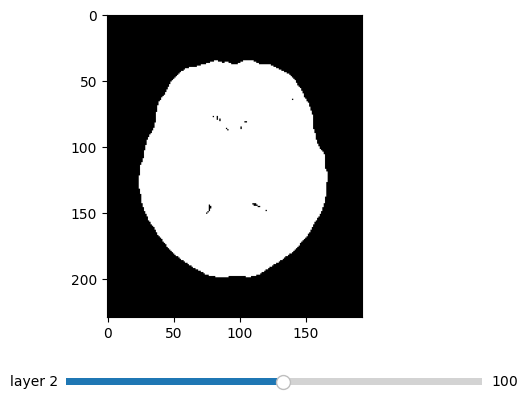

In [ ]:
def load_mask(id, hunt):
    mask_path_name = pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, no_cerebellum=False, absolute=True)
    mask, _ = nfc.load_nifti(mask_path_name)
    return mask

def load_img_and_mask(id, hunt):
    img_path_name = pil.get_registered_to_template_image_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True)
    mask_path_name = pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, no_cerebellum=False, absolute=True)

    img, _ = nfc.load_nifti(img_path_name)
    mask, _ = nfc.load_nifti(mask_path_name)
    return img, mask

def load_mask_prep_mni(id, hunt):
    img_path_name = cts.get_registered_image_path_name(hunt, id)
    img, _ = nfc.load_nifti(img_path_name)
    mask = np.where(img>0.01, 1, 0)
    return mask

def load_mask_prep(id, hunt):
    img_path_name = pil.get_preprocessed_image_path_name(hunt, id, absolute=True)
    img, _ = nfc.load_nifti(img_path_name)
    mask = np.where(img>0, 1, 0)
    return mask

def find_start_end_layer(img, min_tissue=0.1, axis=0):
    start = 0
    end = img.shape[axis]
    max_area = np.prod(np.delete(img.shape, axis))

    for i in range(img.shape[axis]):
        if np.sum(img[i])/max_area >= min_tissue:
            start = i
            break

    for i in range(img.shape[axis]-1, 0, -1):
        if np.sum(img[i])/max_area >= min_tissue:
            end = i
            break
    
    return start, end

def create_start_end_list(matchin_ids, min_tissue=0.15, axis=0):
    layer_start_end = np.zeros((len(matchin_ids)*2, 2))

    for i, id in enumerate(tqdm(matchin_ids)):
        for j, hunt in enumerate([3,4]):  
            # mask = load_mask(id, hunt)
            mask = load_mask_prep_mni(id, hunt)
            layer_start_end[i*2+j] = find_start_end_layer(mask, min_tissue=min_tissue, axis=axis)

    return layer_start_end

# %matplotlib widget

mask = load_mask_prep("00039", 3)
fc.imgshow_3D("", mask)

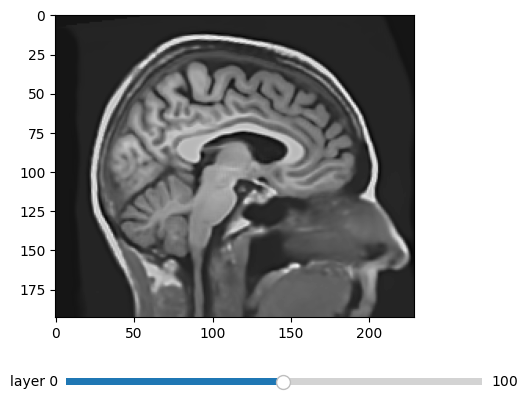

 61%|██████    | 427/703 [02:24<01:37,  2.82it/s]

In [ ]:


matchin_ids = pil.get_matching_ids()

img, mask = load_img_and_mask(matchin_ids[0], 3)
fc.imgshow_3D("", img, mooving_plane=0)


layer_start_end = create_start_end_list(matchin_ids)

In [ ]:

mean_slide = np.mean(layer_start_end, axis=0)
median_slide = np.median(layer_start_end, axis=0)
std_slide = np.std(layer_start_end, axis=0)
min_slide = np.min(layer_start_end, axis=0)
max_slide = np.max(layer_start_end, axis=0)

print(f"min_slide: {min_slide}")
print(f"max_slide: {max_slide}")
print(f"mean_slide: {mean_slide}")
print(f"median_slide: {median_slide}")
print(f"std_slide: {std_slide}")

arg_min = np.argmin(layer_start_end, axis=0)
arg_max = np.argmax(layer_start_end, axis=0)

print(f"{matchin_ids[arg_min[0]//2]} start: {layer_start_end[arg_min[0]][0]}")
print(f"{matchin_ids[arg_min[1]//2]} end: {layer_start_end[arg_min[1]][1]}")

print(f"{matchin_ids[arg_max[0]//2]} start: {layer_start_end[arg_max[0]][0]}")
print(f"{matchin_ids[arg_max[1]//2]} end: {layer_start_end[arg_max[1]][1]}")

# print(np.argmax(layer_start_end, axis=0))

# empieza entes 237
# termina entes 175


# empieza tarde 175
# termina tarde 47


# ------------------------ PREP
# ------------ min_tissue=0.1, axis=0
# min_slide: [ 28. 145.]
# max_slide: [ 44. 164.]
# mean_slide: [ 35.4694 156.0228]
# median_slide: [ 35. 156.]
# std_slide: [2.9532 3.368 ]
# 04877 start: 28.0
# 03528 end: 145.0
# 03528 start: 44.0
# 00381 end: 164.0

# ------------ min_tissue=0.15, axis=0
# min_slide: [ 33. 140.]
# max_slide: [ 50. 159.]
# mean_slide: [ 40.4196 151.1714]
# median_slide: [ 40. 151.]
# std_slide: [3.1679 3.5304]
# 04044 start: 33.0
# 03528 end: 140.0
# 03528 start: 50.0
# 00381 end: 159.0

# ------------------------ PREP MNI
# ------------ min_tissue=0.15, axis=0
# min_slide: [ 32. 157.]
# max_slide: [ 35. 160.]
# mean_slide: [ 33.5754 158.4018]
# median_slide: [ 34. 158.]
# std_slide: [0.5357 0.5478]
# 01067 start: 32.0
# 00510 end: 157.0
# 00046 start: 35.0
# 00244 end: 160.0

# start = 34, end = 157
# nb_slides = 123
# nb_images rgb = 41 


min_slide: [ 32. 157.]
max_slide: [ 35. 160.]
mean_slide: [ 33.5754 158.4018]
median_slide: [ 34. 158.]
std_slide: [0.5357 0.5478]
01067 start: 32.0
00510 end: 157.0
00046 start: 35.0
00244 end: 160.0
